<a href="https://colab.research.google.com/github/pylclgemail-bit/Fake-job-detection-project/blob/main/Fake_job_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install pandas numpy matplotlib seaborn scikit-learn nltk gradio shap

In [ ]:
!pip install -q kagglehub

import kagglehub
import pandas as pd
import os

# Download dataset
path = kagglehub.dataset_download(
    "shivamb/real-or-fake-fake-jobposting-prediction"
)

# Load dataset
df = pd.read_csv(
    os.path.join(path, "fake_job_postings.csv")
)

# Select 50 real and 50 fake jobs
real_jobs = df[df['fraudulent'] == 0].sample(
    n=50, random_state=42
)

fake_jobs = df[df['fraudulent'] == 1].sample(
    n=50, random_state=42
)

# Combine and shuffle
df = pd.concat([real_jobs, fake_jobs]).sample(
    frac=1, random_state=42
).reset_index(drop=True)

print("Total Job Postings:", len(df))
print("\nReal vs Fake Jobs:")
print(df['fraudulent'].value_counts())

df.head()

Using Colab cache for faster access to the 'real-or-fake-fake-jobposting-prediction' dataset.
Total Job Postings: 100

Real vs Fake Jobs:
fraudulent
1    50
0    50
Name: count, dtype: int64


,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,17672,Home Based Payroll Typist/Data Entry Clerks Po...,"US, MS, Aberdeen",Clerical,NaN,NaN,We have several openings available in this are...,"Basic computer and typing skills, ability to s...",All you need is access to the Internet and you...,0,0,0,NaN,NaN,NaN,NaN,NaN,1
1,17778,Hiring Part-Time Workers (CASH PAYING),"US, CA, Los Angeles",NaN,NaN,NaN,Hiring Part-Time Workers (CASH PAYING)You can ...,No any experience #URL_5a85681305d45d339fe0299...,NaN,0,0,0,Part-time,NaN,NaN,NaN,NaN,1
2,17561,Job for freelancer working in Saudi Arabia,"SA, 01, Murabba Riyadh",IT Administrator / Developer,NaN,NaN,Hundreds of Freelance Jobs available every mon...,Freelancer working in Saudi Arabia.,NaN,0,0,1,Full-time,Entry level,Master's Degree,Computer Networking,Information Technology,1
3,12834,Web Designer / Front End Developer,"GR, I, Athens",NaN,NaN,"""Only stupid questions create wealth"" - Gary ...",We are looking for a skilled web designer / fr...,Web and UI/UX designBe able to develop custom ...,"This is a full-time, in house position.Full de...",0,1,1,Other,NaN,NaN,Design,Design,0
4,6545,Practice Manager,"US, TX, Cleburne",Admin,NaN,NaN,Exciting opportunity for experienced practice ...,Minimum 3 years management experience in medic...,Medical/Dental/VisionVacation/Sick Leave,0,1,0,Full-time,Mid-Senior level,High School or equivalent,Medical Practice,Administrative,0


In [ ]:
# Check missing values
print("Missing Values Before Cleaning:")
print(df.isnull().sum())

Missing Values Before Cleaning:
job_id                  0
title                   0
location                3
department             60
salary_range           79
company_profile        44
description             0
requirements           23
benefits               40
telecommuting           0
has_company_logo        0
has_questions           0
employment_type        24
required_experience    47
required_education     52
industry               30
function               40
fraudulent              0
dtype: int64


In [ ]:
# Fill missing values
df = df.fillna("")

print("Missing Values After Cleaning:")
print(df.isnull().sum())

Missing Values After Cleaning:
job_id                 0
title                  0
location               0
department             0
salary_range           0
company_profile        0
description            0
requirements           0
benefits               0
telecommuting          0
has_company_logo       0
has_questions          0
employment_type        0
required_experience    0
required_education     0
industry               0
function               0
fraudulent             0
dtype: int64


In [ ]:
# Combine important text columns
df['combined_text'] = (
    df['title'].astype(str) + " " +
    df['company_profile'].astype(str) + " " +
    df['description'].astype(str) + " " +
    df['requirements'].astype(str) + " " +
    df['benefits'].astype(str)
)

df[['title', 'combined_text']].head()

,title,combined_text
0,Home Based Payroll Typist/Data Entry Clerks Po...,Home Based Payroll Typist/Data Entry Clerks Po...
1,Hiring Part-Time Workers (CASH PAYING),Hiring Part-Time Workers (CASH PAYING) Hiring...
2,Job for freelancer working in Saudi Arabia,Job for freelancer working in Saudi Arabia Hu...
3,Web Designer / Front End Developer,"Web Designer / Front End Developer ""Only stupi..."
4,Practice Manager,Practice Manager Exciting opportunity for exp...


In [ ]:
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

df['cleaned_text'] = df['combined_text'].apply(clean_text)

print("Text Cleaning Completed!")

df[['title', 'cleaned_text']].head()

Text Cleaning Completed!


,title,cleaned_text
0,Home Based Payroll Typist/Data Entry Clerks Po...,home based payroll typist data entry clerks po...
1,Hiring Part-Time Workers (CASH PAYING),hiring part time workers cash paying hiring pa...
2,Job for freelancer working in Saudi Arabia,job for freelancer working in saudi arabia hun...
3,Web Designer / Front End Developer,web designer front end developer only stupid q...
4,Practice Manager,practice manager exciting opportunity for expe...


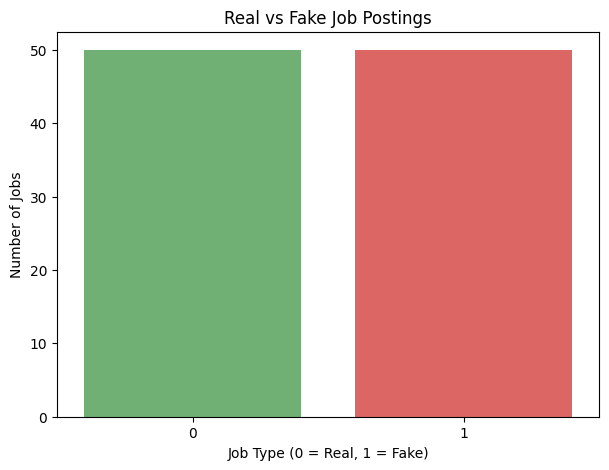

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(
    x='fraudulent',
    data=df,
    hue='fraudulent',
    palette=['#66BB6A', '#EF5350'],
    legend=False
)

plt.title("Real vs Fake Job Postings")
plt.xlabel("Job Type (0 = Real, 1 = Fake)")
plt.ylabel("Number of Jobs")

plt.show()

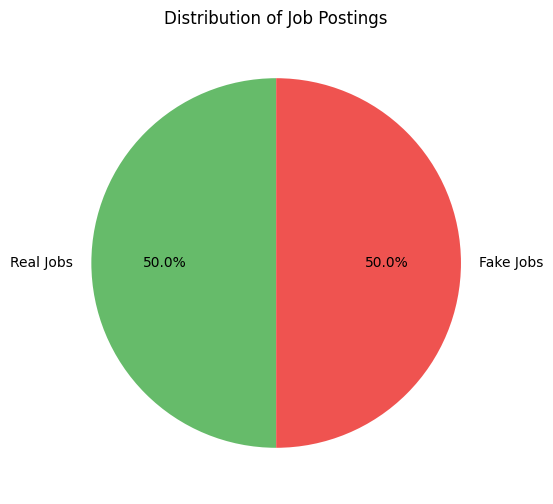

In [ ]:
labels = ['Real Jobs', 'Fake Jobs']
sizes = df['fraudulent'].value_counts().reindex([0, 1]).values

plt.figure(figsize=(6, 6))

plt.pie(
    sizes,
    labels=labels,
    autopct='%1.1f%%',
    colors=['#66BB6A', '#EF5350'],
    startangle=90
)

plt.title("Distribution of Job Postings")
plt.show()

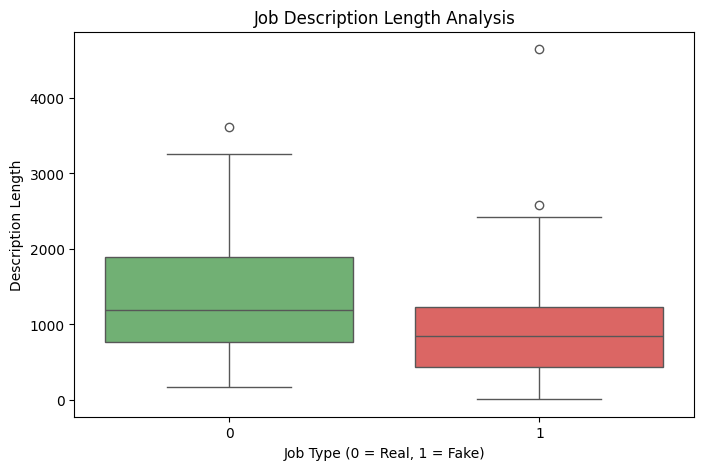

In [ ]:
df['description_length'] = df['description'].apply(
    lambda x: len(str(x))
)

plt.figure(figsize=(8, 5))

sns.boxplot(
    x='fraudulent',
    y='description_length',
    data=df,
    hue='fraudulent',
    palette=['#66BB6A', '#EF5350'],
    legend=False
)

plt.title("Job Description Length Analysis")
plt.xlabel("Job Type (0 = Real, 1 = Fake)")
plt.ylabel("Description Length")

plt.show()

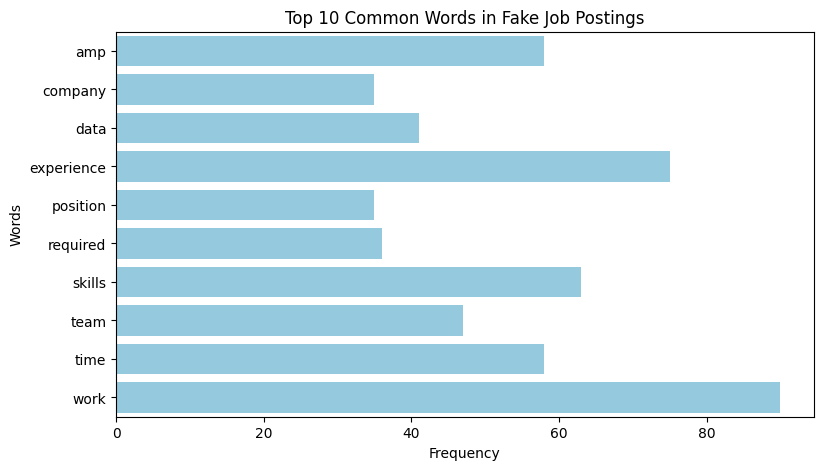

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

fake_text = df[df['fraudulent'] == 1]['cleaned_text']

vectorizer = CountVectorizer(
    stop_words='english',
    max_features=10
)

word_matrix = vectorizer.fit_transform(fake_text)

word_counts = word_matrix.sum(axis=0).A1
words = vectorizer.get_feature_names_out()

plt.figure(figsize=(9, 5))

sns.barplot(
    x=word_counts,
    y=words,
    color='skyblue'
)

plt.title("Top 10 Common Words in Fake Job Postings")
plt.xlabel("Frequency")
plt.ylabel("Words")

plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

# Input features
X = df['cleaned_text']

# Output labels
y = df['fraudulent'].astype(int)

# Split dataset into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", len(X_train))
print("Testing Data:", len(X_test))

Training Data: 80
Testing Data: 20


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    stop_words='english',
    max_features=3000
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF Vectorization Completed!")
print("Training Shape:", X_train_tfidf.shape)

TF-IDF Vectorization Completed!
Training Shape: (80, 3000)


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB

# Create models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "Naive Bayes": MultinomialNB()
}

# Train models
for name, model in models.items():
    model.fit(X_train_tfidf, y_train)
    print(name, "Training Completed!")

Logistic Regression Training Completed!
Random Forest Training Completed!
Naive Bayes Training Completed!


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import pandas as pd

results = []

for name, model in models.items():

    predictions = model.predict(X_test_tfidf)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

results_df = pd.DataFrame(results)

display(results_df.round(3))

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.85,1.000,0.7,0.824
1,Random Forest,0.75,0.778,0.7,0.737
2,Naive Bayes,0.85,1.000,0.7,0.824


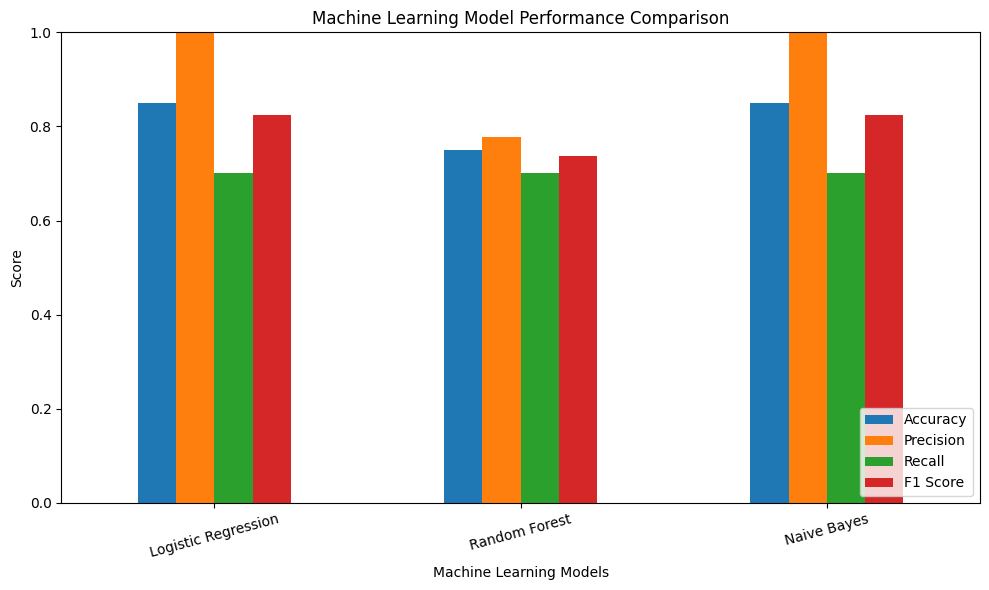

In [ ]:
import matplotlib.pyplot as plt

results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Machine Learning Model Performance Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()

plt.show()

In [ ]:
# Select model with highest F1 score
best_model_name = results_df.loc[
    results_df['F1 Score'].idxmax(), 'Model'
]

best_model = models[best_model_name]

print("Best Performing Model:", best_model_name)

Best Performing Model: Logistic Regression


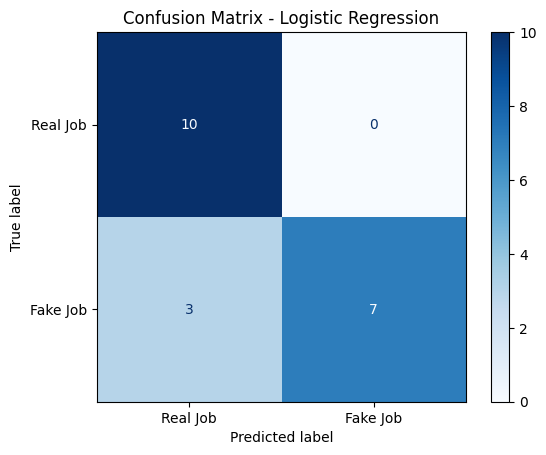

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_pred = best_model.predict(X_test_tfidf)

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Real Job", "Fake Job"]
)

disp.plot(cmap="Blues")

plt.title("Confusion Matrix - " + best_model_name)
plt.show()

In [ ]:
def predict_job(description):
    cleaned = clean_text(description)
    text_vector = tfidf.transform([cleaned])

    prediction = best_model.predict(text_vector)[0]
    confidence = best_model.predict_proba(text_vector)[0].max() * 100

    if prediction == 1:
        print("⚠️ Potentially Fake Job")
    else:
        print("✅ Likely Genuine Job")

    print(f"Model Confidence: {confidence:.2f}%")

# Test
predict_job("Earn 50000 weekly. No experience needed. Pay registration fee.")

⚠️ Potentially Fake Job
Model Confidence: 56.88%


In [ ]:
import gradio as gr

def check_job(description):
    cleaned = clean_text(description)
    vector = tfidf.transform([cleaned])

    prediction = best_model.predict(vector)[0]
    confidence = best_model.predict_proba(vector)[0].max() * 100

    result = "⚠️ Potentially Fake Job" if prediction == 1 else "✅ Likely Genuine Job"

    warnings = []
    text = description.lower()

    if "registration fee" in text:
        warnings.append("Registration fee requested")
    if "no experience" in text:
        warnings.append("No experience required")
    if "earn" in text and "weekly" in text:
        warnings.append("Check salary claims")

    risk = "\n".join(warnings) if warnings else "No common warning phrases found"

    return f"{result}\n\nModel Confidence: {confidence:.2f}%\n\nRisk Indicators:\n{risk}"

app = gr.Interface(
    fn=check_job,
    inputs=gr.Textbox(lines=6, label="Enter Job Description"),
    outputs=gr.Textbox(label="Analysis Result"),
    title="AI-Based Fake Job Detection System",
    description="Analyze job postings using Python and Machine Learning."
)

app.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://213136a7103e3b1c73.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
